# FRTB desk eligibility: the P&L attribution test and desk back-testing (C13)

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 03 of this topic (backtests and the traffic light)
- **Reading time:** about 40 minutes

**Question:** Of six deficiencies planted in a desk's risk model, which does the FRTB P&L attribution test catch, which does it miss, and what does the desk-level back-test add?

## Objectives

By the end of this notebook you can:

- state the two statistics of the profit-and-loss attribution (PLA) test, the Spearman correlation and the Kolmogorov-Smirnov distance, compute them by hand and obtain the engine's values;
- read the PLA zones and say why the engine decides the boundaries on integers;
- say what a desk-level back-test counts, what its limits are, and how a missing value is treated;
- read, for six planted deficiencies on a synthetic desk, which ones the PLA catches, which it misses and which statistic does the catching;
- give the 95 percent interval of a detection rate and say what a Monte Carlo share on known truth can and cannot claim.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools, print the versions they run with and fix the words this notebook prints for the engine's
# lights
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Case C13 asks what a validator concludes when a desk's risk model has a known deficiency. The data is **synthetic by design**: a generator produces the hypothetical P&L (HPL, from the exact revaluation of the desk) and the risk-theoretical P&L (RTPL, from the risk model) of a two-factor spread desk, and a deficiency is planted only in the risk model. Because the truth is known, each result is shown beside the deficiency it is meant to detect. This is not the book of any real desk and says nothing about any bank.

- `data/derived/C13/models-generator.json`: the generator, its parameters, the PLA thresholds and the desk limits.
- `data/derived/C13/<variant>.json` for six variants: `none` (no deficiency, the size of the test), `missing-basis`, `stale-volatility`, `wrong-correlation`, `omitted-factor` and `time-misalignment`. Each holds 1,000 replications of 250 days summarised (zones, detection counts, exception counts) and **one example replication** with its two P&L series of 250 days, the replication that has the median Spearman statistic.
- `data/derived/C11/fx-2008.json` supplies real data for the desk-level back-test of step 4.

The notebook recomputes the test on the six example replications and reads the summaries of the 1,000. The next cell loads the files and prints the planted deficiencies.

In [2]:
# Load the generator document and the six variants of case C13, and print what each one plants and what it
# should fail
ROOT = Path("../../..").resolve()
VARIANTS = ("none", "missing-basis", "stale-volatility", "wrong-correlation", "omitted-factor", "time-misalignment")
C13 = ROOT / "data" / "derived" / "C13"
c13 = {v: json.loads((C13 / f"{v}.json").read_text(encoding="utf-8")) for v in VARIANTS}
generator = json.loads((C13 / "models-generator.json").read_text(encoding="utf-8"))["fit"]
INTENDED = {"none": "none", "spearman": "Spearman", "ks": "KS", "both": "both", "either": "either"}

print("PLA thresholds:", {k: v for k, v in generator["pla_thresholds"].items() if k != "reference"})
print("desk limits:", {d["alpha"]: d["limit_exceptions"] for d in generator["desk_limits"]})
for v in VARIANTS:
    known = c13[v]["outputs"]["known_deficiency"]
    params = [(p["name"], p["value"]) for p in known["parameters"]]
    print(f"{v:18s} planted: {'yes' if known['planted'] else 'no':3s} | "
          f"meant to fail: {INTENDED.get(known['intended_to_fail'], known['intended_to_fail']):9s} | {params}")

PLA thresholds: {'spearman_green': 0.8, 'spearman_red': 0.7, 'ks_green': 0.09, 'ks_red': 0.12, 'ecdf_step': 0.004, 'window_days': 250}
desk limits: {0.025: 30, 0.01: 12}
none               planted: no  | meant to fail: none      | []
missing-basis      planted: yes | meant to fail: Spearman  | [('basis_sd_share', 0.65)]
stale-volatility   planted: yes | meant to fail: KS        | [('vol_lag_days', 20.0)]
wrong-correlation  planted: yes | meant to fail: either    | [('correlation_error', 0.3)]
omitted-factor     planted: yes | meant to fail: Spearman  | [('omitted_loading_share', 0.6)]
time-misalignment  planted: yes | meant to fail: Spearman  | [('lag_days', 1.0)]


## Method

### Step 1: the PLA test

The FRTB internal-models approach (Basel Framework MAR32.36 to MAR32.42) asks whether the risk model explains the desk's P&L. On the most recent 250 days it compares the risk-theoretical P&L with the hypothetical one in two ways. The **Spearman correlation** is the Pearson correlation of the ranks, so it asks whether the two series order the days alike:

$$r_S = \frac{\operatorname{cov}(R_{HPL}, R_{RTPL})}{\sigma_{R_{HPL}}\,\sigma_{R_{RTPL}}}$$

The **Kolmogorov-Smirnov** distance asks whether the two series have the same distribution, with the empirical distribution function $F(x) = 0.004\cdot\#\{\text{observations} \le x\}$:

$$KS = \sup_x \left| F_{RTPL}(x) - F_{HPL}(x) \right|$$

The zone is **green** if $r_S > 0.80$ and $KS < 0.09$, **red** if $r_S < 0.70$ or $KS > 0.12$, **amber** otherwise. Red makes the desk ineligible for the internal models approach; amber keeps it with a capital surcharge. The engine's `pla_spearman`, `pla_ks`, `pla_zone` and `pla_test` implement these. The cell computes both statistics by hand on the example replication of the `none` variant, with SciPy's rank correlation and a count of the steps of the two distribution functions, and prints them beside the engine's.

In [3]:
# Spearman and Kolmogorov-Smirnov by hand on the example replication of the "none" variant, and the engine's
# PLA test
from riskvalidation.market.frtb import pla_ks, pla_spearman, pla_zone
from riskvalidation.validation.market import pla_test

example = c13["none"]["outputs"]["example"]
hpl, rtpl = np.array(example["hpl"]), np.array(example["rtpl"])
print(f"replication {example['replication_index']}: {hpl.size} days")
print(f"HPL sd {hpl.std():.5f} | RTPL sd {rtpl.std():.5f}")
points = np.union1d(hpl, rtpl)
ecdf_hpl = np.searchsorted(np.sort(hpl), points, side="right") * 0.004
ecdf_rtpl = np.searchsorted(np.sort(rtpl), points, side="right") * 0.004
print(f"by hand: Spearman {stats.spearmanr(hpl, rtpl).statistic:.6f} | KS {np.max(np.abs(ecdf_rtpl - ecdf_hpl)):.3f}")
rho, ks = pla_spearman(hpl, rtpl), pla_ks(hpl, rtpl)
print(f"engine: Spearman {rho:.6f} | KS {ks:.3f} | zone {LIGHT[pla_zone(rho, ks)]}")
result = pla_test(hpl, rtpl, model_id="desk-risk-model")
print(f"pla_test: statistic {result.statistic:.6f} | metric {result.metric:.3f} | {LIGHT[result.light.value]}")

replication 9: 250 days
HPL sd 0.00529 | RTPL sd 0.00522
by hand: Spearman 0.992332 | KS 0.032
engine: Spearman 0.992332 | KS 0.032 | zone green
pla_test: statistic 0.992332 | metric 0.032 | green


### Step 2: boundaries decided on integers

A zone boundary is a hard line, and a statistic that falls exactly on it must not be moved by floating-point rounding. The KS distance is an integer count of steps over 250, so $KS < 0.09$ is $\text{gap} \le 22$ and $KS > 0.12$ is $\text{gap} \ge 31$. The Spearman boundaries 0.80 and 0.70 are decided by `compare_spearman`, which works on the doubled average ranks as integers and compares $S_{xy}^2$ with $\text{threshold}^2\,S_{xx}S_{yy}$ in exact rational arithmetic, returning 1, 0 or -1 for above, on and below. `pla_zone_exact` uses both and agrees with the float rule `pla_zone` except where a float quotient would sit on a boundary. The cell prints, for the example replication of each variant, the step gap, the comparison with each Spearman boundary and the two zone rules.

In [4]:
# For each variant's example: the KS step gap, the exact comparison with each Spearman boundary, and both
# zone rules
from riskvalidation.market.frtb import compare_spearman, pla_zone_exact

print(f"{'variant':18s} {'Spearman':>9s} {'KS':>6s} {'gap':>4s} {'vs 0.80':>8s} {'vs 0.70':>8s}  float exact")
for v in VARIANTS:
    example = c13[v]["outputs"]["example"]
    h, r = np.array(example["hpl"]), np.array(example["rtpl"])
    rho, ks = pla_spearman(h, r), pla_ks(h, r)
    against = (compare_spearman(h, r, 0.80), compare_spearman(h, r, 0.70))
    float_zone, exact_zone = LIGHT[pla_zone(rho, ks)], LIGHT[pla_zone_exact(h, r)]
    gap = round(ks * 250)
    print(f"{v:18s} {rho:9.4f} {ks:6.3f} {gap:4d} {against[0]:8d} {against[1]:8d}  {float_zone:>8s} {exact_zone:>8s}")

variant             Spearman     KS  gap  vs 0.80  vs 0.70  float exact
none                  0.9923  0.032    8        1        1     green    green
missing-basis         0.7107  0.104   26       -1        1     amber    amber
stale-volatility      0.9793  0.044   11        1        1     green    green
wrong-correlation     0.9865  0.144   36        1        1       red      red
omitted-factor        0.7749  0.080   20       -1        1     amber    amber
time-misalignment    -0.0065  0.028    7       -1       -1       red      red


### Step 3: the six example replications

One replication is one draw, but it shows the mechanism: each deficiency leaves a different mark on the two statistics. The cell runs `pla_test` on the example of every variant and draws the risk-theoretical P&L against the hypothetical one, coloured by the PLA zone. A **missing basis** or an **omitted factor** adds P&L the model cannot see, which weakens the rank correlation; a **time misalignment** destroys the day-by-day match completely; a **wrong correlation** keeps the order of the days but changes the spread of the model's P&L, which the KS distance sees and the Spearman correlation does not; a **stale volatility** changes little of either.

none               Spearman  0.9923 | KS 0.032 | zone green
missing-basis      Spearman  0.7107 | KS 0.104 | zone amber
stale-volatility   Spearman  0.9793 | KS 0.044 | zone green
wrong-correlation  Spearman  0.9865 | KS 0.144 | zone red
omitted-factor     Spearman  0.7749 | KS 0.080 | zone amber
time-misalignment  Spearman -0.0065 | KS 0.028 | zone red


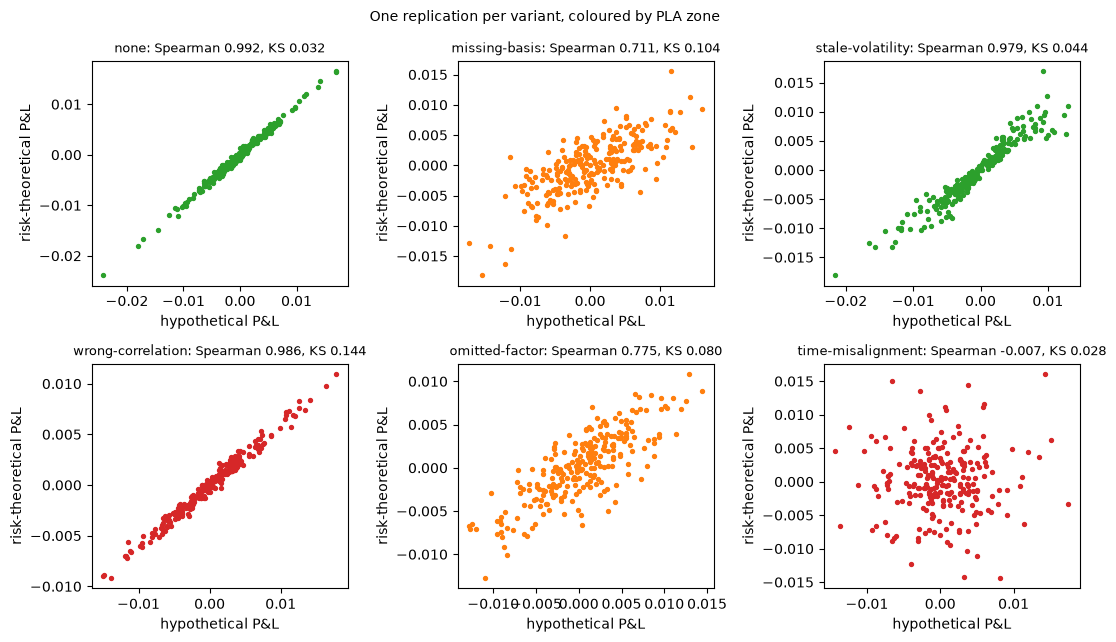

In [5]:
# Run pla_test on each variant's example replication and draw the risk-theoretical against the hypothetical P&L
colour = {"green": "tab:green", "amber": "tab:orange", "red": "tab:red"}
fig, axes = plt.subplots(2, 3, figsize=(11, 6.5))
for ax, v in zip(axes.ravel(), VARIANTS):
    example = c13[v]["outputs"]["example"]
    h, r = np.array(example["hpl"]), np.array(example["rtpl"])
    fresh = pla_test(h, r, model_id="desk-risk-model")
    ax.scatter(h, r, s=8, color=colour[fresh.light.value])
    ax.set_title(f"{v}: Spearman {fresh.statistic:.3f}, KS {fresh.metric:.3f}", fontsize=9)
    ax.set_xlabel("hypothetical P&L")
    ax.set_ylabel("risk-theoretical P&L")
    print(f"{v:18s} Spearman {fresh.statistic:7.4f} | KS {fresh.metric:.3f} | zone {LIGHT[fresh.light.value]}")
fig.suptitle("One replication per variant, coloured by PLA zone", fontsize=10)
fig.tight_layout()
plt.show()

Each panel plots the risk model's P&L against the true one, day by day. The clean desk lies on the diagonal (Spearman 0.9923, KS 0.032, green). `missing-basis` (0.7107, 0.104) and `omitted-factor` (0.7749, 0.080) scatter around it and fall into the amber zone on the Spearman side. `stale-volatility` (0.9793, 0.044) is almost indistinguishable from the clean desk and stays green. `wrong-correlation` keeps the ranks (Spearman 0.9865) but its cloud is the wrong shape and its KS of 0.144 is past the red limit, so the colour comes from KS alone. `time-misalignment` is a shapeless cloud with a Spearman of -0.0065, red. A single replication shows the mechanism, not the frequency: the last step counts how often each pattern occurs.

The time misalignment is the easiest deficiency to reproduce by hand. The next cell shifts the risk-theoretical P&L of the `none` example by 0 to 5 days with `np.roll`, which turns a correct model into one that is late by that many days, and runs `pla_test` on each shift. The figure draws the Spearman correlation against the shift with the 0.80 and 0.70 boundaries.

shift 0 days: Spearman  0.9923 | KS 0.032 | green
shift 1 days: Spearman  0.0773 | KS 0.032 | red
shift 2 days: Spearman  0.0541 | KS 0.032 | red
shift 3 days: Spearman -0.0200 | KS 0.032 | red
shift 4 days: Spearman -0.0059 | KS 0.032 | red
shift 5 days: Spearman -0.0232 | KS 0.032 | red


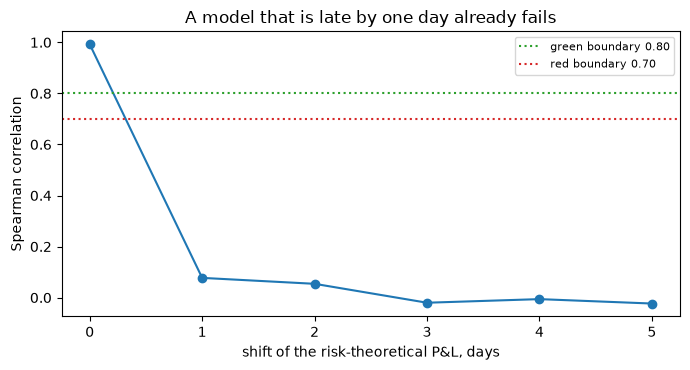

In [6]:
# Shift the risk-theoretical P&L of the "none" example by 0 to 5 days and run the PLA test on each shift
shifts = np.arange(6)
rows = [pla_test(hpl, np.roll(rtpl, int(s)), model_id="desk-risk-model") for s in shifts]
for s, row in zip(shifts, rows):
    print(f"shift {s} days: Spearman {row.statistic:7.4f} | KS {row.metric:.3f} | {LIGHT[row.light.value]}")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(shifts, [row.statistic for row in rows], marker="o")
ax.axhline(0.80, color="tab:green", linestyle=":", label="green boundary 0.80")
ax.axhline(0.70, color="tab:red", linestyle=":", label="red boundary 0.70")
ax.set_xlabel("shift of the risk-theoretical P&L, days")
ax.set_ylabel("Spearman correlation")
ax.set_title("A model that is late by one day already fails")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

A delay of one day takes the Spearman correlation from 0.9923 to 0.0773 and the zone from green to red, and further delays do not change the picture: the days of a P&L series are almost unrelated to their neighbours, so a model that is one day late explains nothing about the day it is scored on. The KS distance stays at 0.032 for every shift, because rolling the series reorders the same values and leaves their distribution untouched. The figure shows why the PLA needs two statistics: the KS distance is blind to order and the Spearman correlation is blind to the shape of the distribution. It does not say how late a real model could be; the synthetic variant uses a lag of one day.

### Step 4: the desk-level back-test

Besides the PLA test, an internal-models desk must back-test its VaR at the desk level (MAR32.18 to MAR32.19): over the most recent 250 days it counts the days on which the loss exceeded the desk's one-day VaR, and the desk **moves to the standardised approach** if the count exceeds 12 at 99 percent or 30 at 97.5 percent. The engine has `desk_exception_limit(alpha)`, `desk_exceptions(loss, var, missing_as_exception)` and `desk_backtest(loss, var, alpha, basis)`. A missing loss or VaR counts as an exception by default, since the framework treats a missing value as an outlier for the bank-wide test and the engine keeps the same rule for a desk behind a flag. There is no amber: the light is red above the limit and green otherwise.

The synthetic desks of C13 commit their exception counts but not the loss and VaR series, so this step uses real data: the euro position of `fx-2008` as a one-position desk, its realised loss and the committed `ewma` VaR for the last 250 of its 251 days. The cell shows the count, the limit and the light at both levels, then blanks two days to show the treatment of missing values.

In [7]:
# Desk back-test of the euro position (a one-position desk): exceptions in the last 250 days against the limit
from riskvalidation.market.frtb import desk_exception_limit, desk_exceptions
from riskvalidation.validation.market import desk_backtest

fx = json.loads((ROOT / "data" / "derived" / "C11" / "fx-2008.json").read_text(encoding="utf-8"))
fx_loss = np.array(fx["outputs"]["grid"]["realised_loss"]["loss"])
ewma = {m["model_id"]: m for m in fx["outputs"]["models"]}["ewma"]
for level in ewma["by_level"]:
    alpha = level["alpha"]
    outcome = desk_backtest(fx_loss, np.array(level["var"]), alpha, model_id="ewma", basis="HPL")
    print(f"alpha {alpha}: exceptions in the last 250 days {int(outcome.statistic)} | "
          f"limit {int(outcome.metric)} | {LIGHT[outcome.light.value]}")

var = np.array(ewma["by_level"][0]["var"])
blanked = fx_loss.copy()
blanked[[100, 101]] = np.nan
print("limits:", {a: desk_exception_limit(a) for a in (0.01, 0.025)})
print(f"missing counted as exceptions: {desk_exceptions(blanked[-250:], var[-250:])}")
print(f"missing ignored: {desk_exceptions(blanked[-250:], var[-250:], missing_as_exception=False)}")
print(f"no missing values: {desk_exceptions(fx_loss[-250:], var[-250:])}")

alpha 0.01: exceptions in the last 250 days 3 | limit 12 | green
alpha 0.025: exceptions in the last 250 days 8 | limit 30 | green
limits: {0.01: 12, 0.025: 30}
missing counted as exceptions: 5
missing ignored: 3
no missing values: 3


Treating the euro position of `fx-2008` as a one-position desk, the EWMA VaR has 3 exceptions in the last 250 days at 99 percent against a limit of 12, and 8 at 97.5 percent against a limit of 30: green at both levels, with room to spare. The three last lines show the treatment of a missing value: with two days of missing P&L the count is 5 when a missing value counts as an exception, the engine's default, and 3 when it is ignored, the same as with no missing values. The desk test has no amber and counts only the number of days over the VaR, with no regard to their size, so it can say nothing about a desk whose model is wrong in the middle of the distribution.

### Step 5: how often each deficiency is caught

What a validator needs to know is not whether the test caught one replication but how **often**. Each variant ran 1,000 replications, and the artifact records how many were amber or red on the PLA (the deficiency is **caught**), how many were red, how many exceeded the desk limit at 99 percent, and which statistic flagged them. For the variant with no deficiency the same share is the **false-alarm rate** (the size of the test). A share $\hat p$ from $n$ replications carries Monte Carlo error, and its standard error is zero at 0 and 1, so the interval used is the Wilson score interval, which stays inside [0, 1] and is not degenerate at the edges (Brown, Cai and DasGupta, 2001). The cell reads the counts of each variant and asks the engine's `wilson_interval` for the 95 percent interval of the caught share; the figure draws the three shares.

variant                caught    red  desk>12
none                    0.000  0.000    0.000
                   flagged by Spearman 0, KS 0
                   95% interval: 0.0000 to 0.0038
missing-basis           0.960  0.575    0.565
                   flagged by Spearman 919, KS 867
                   95% interval: 0.9460 to 0.9705
stale-volatility        0.000  0.000    0.005
                   flagged by Spearman 0, KS 0
                   95% interval: 0.0000 to 0.0038
wrong-correlation       1.000  0.913    0.953
                   flagged by Spearman 0, KS 1000
                   95% interval: 0.9962 to 1.0000
omitted-factor          0.901  0.043    0.064
                   flagged by Spearman 805, KS 448
                   95% interval: 0.8809 to 0.9180
time-misalignment       1.000  1.000    0.000
                   flagged by Spearman 1000, KS 0
                   95% interval: 0.9962 to 1.0000


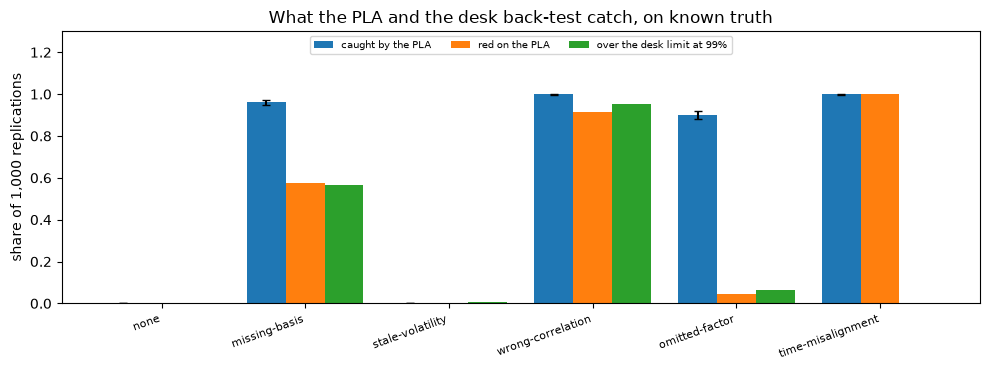

In [8]:
# Detection shares of the 1,000 replications per variant with the engine's Wilson interval, and the shares drawn
from riskvalidation.harness.rates import wilson_interval

det = {v: c13[v]["outputs"]["detection"] for v in VARIANTS}
caught = np.array([det[v]["share_amber_or_red"] for v in VARIANTS])
red = np.array([det[v]["share_red"] for v in VARIANTS])
desk = np.array([c13[v]["impact"]["share_desk_over_limit_99"]["value"] for v in VARIANTS])
low, high = np.array([wilson_interval(det[v]["n_amber_or_red"], det[v]["n_replications"]) for v in VARIANTS]).T
print(f"{'variant':18s} {'caught':>10s} {'red':>6s} {'desk>12':>8s}")
for i, v in enumerate(VARIANTS):
    by = det[v]["by_test"]
    print(f"{v:18s} {caught[i]:10.3f} {red[i]:6.3f} {desk[i]:8.3f}")
    print(f"{'':18s} flagged by Spearman {by['spearman_flagged']}, KS {by['ks_flagged']}")
    print(f"{'':18s} 95% interval: {low[i]:.4f} to {high[i]:.4f}")

x = np.arange(len(VARIANTS))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(x - 0.27, caught, 0.27, yerr=[caught - low, high - caught], capsize=3, label="caught by the PLA")
ax.bar(x, red, 0.27, label="red on the PLA")
ax.bar(x + 0.27, desk, 0.27, label="over the desk limit at 99%")
ax.set_xticks(x, VARIANTS, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("share of 1,000 replications")
ax.set_title("What the PLA and the desk back-test catch, on known truth")
ax.set_ylim(0, 1.3)
ax.legend(fontsize=7, ncol=3, loc="upper center")
fig.tight_layout()
plt.show()

The blue bars are the share of the 1,000 replications that the PLA caught (amber or red), with the 95 percent Wilson interval as a black cap. With no deficiency the PLA is amber or red in 0.000 of the replications and the upper limit of the interval is 0.0038: it almost never accuses a correct model on this generator. `time-misalignment` and `wrong-correlation` are caught in every replication (interval 0.9962 to 1.0000), `missing-basis` in 0.960 (0.9460 to 0.9705) and `omitted-factor` in 0.901 (0.8809 to 0.9180), but the last one is red in only 0.043 of them. `stale-volatility` is caught in 0.000 of the replications, so a 20-day lag in the volatility input does not show on the P&L comparison. The orange and green bars show that the desk test catches a different subset: 0.953 of `wrong-correlation` and none of `time-misalignment`. A share on a generator with known truth says how the test behaves on these deficiencies; it does not say how often a real desk has one.

## Results

**Answer:** The PLA catches four of the five planted deficiencies almost always and misses the fifth entirely. Time misalignment and wrong correlation are caught in 1.000 of the replications (interval 0.9962 to 1.0000), missing basis in 0.960 and omitted factor in 0.901, with no false alarm on the clean desk (0.000 caught, upper limit 0.0038). Stale volatility is caught in 0.000 of them, although the file marks it as meant to fail on KS, and the desk back-test catches a different subset: 0.953 of the wrong-correlation replications and 0.000 of the time-misaligned ones.

- **The statistics by hand.** On the example replication of the `none` variant (replication 9) the Spearman correlation is 0.992332 and the KS distance 0.032 by hand and by the engine, and the zone is green.
- **Boundaries on integers.** `missing-basis` (Spearman 0.7107, gap 26) and `omitted-factor` (0.7749, gap 20) are amber because their Spearman lies between 0.70 and 0.80 (comparison -1 against 0.80, +1 against 0.70). `wrong-correlation` has a Spearman of 0.9865 and a gap of 36, past the red limit of 31, so it is red on KS alone. `time-misalignment` has a Spearman of -0.0065 and is red. The float rule and the exact rule agree on all six.
- **A one-day delay.** Shifting the risk-theoretical P&L of the clean example by one day takes the Spearman correlation from 0.9923 to 0.0773 and the zone to red, while the KS distance stays at 0.032.
- **The desk back-test.** Treating the euro position of `fx-2008` as a one-position desk, the `ewma` VaR has 3 exceptions in the last 250 days at 0.01 (limit 12) and 8 at 0.025 (limit 30): green at both. With two days of missing P&L the count is 5 when missing values count as exceptions, the default, and 3 when they are ignored.
- **What is caught.** `missing-basis` is flagged by Spearman in 919 replications and by KS in 867 (red in 0.575); `omitted-factor` by Spearman in 805 and KS in 448 (red in only 0.043); `wrong-correlation` by KS in 1000 and never by Spearman; `time-misalignment` by Spearman in 1000 and never by KS.
- **The interval.** The Wilson interval of a share is the interval of a Monte Carlo share on a generator with known truth, for example 0.9460 to 0.9705 for `missing-basis`. It says nothing about how often a real desk has one of these deficiencies.

What this notebook does not show: the capital consequences of an amber or red desk (surcharge or standardised approach), which belong to the regulatory calculators.

## Summary

- The PLA test has two statistics that see different things: the Spearman correlation sees whether the two P&L series order the days alike, the KS distance whether they have the same distribution. A deficiency can break one and leave the other intact, so the joint zone takes the worse of the two.
- Zone boundaries are decided on integers (a step gap for KS, exact rational arithmetic for Spearman), so a value on a boundary is never moved by rounding.
- A model that is one day late has a Spearman correlation near zero and the same KS distance as a correct one, which is the clearest example of why both statistics are needed.
- The desk back-test counts exceptions against a limit (12 at 99 percent, 30 at 97.5 percent) with no amber, and a missing value counts as an exception by default.
- On a synthetic desk with a planted deficiency the truth is known, so the test can be judged by its detection rate and its false-alarm rate, each with an interval. The PLA catches some deficiencies almost always and others never, and the desk back-test catches a different subset.

**What to try next.** Change the lag of the shift cell to a fraction of the series by blending `rtpl` with a rolled copy of itself and find the mix at which the zone turns amber; then read the SDD's description of the generator.

## References

- Basel Committee on Banking Supervision, Basel Framework, MAR32.18 to MAR32.19 (desk-level back-testing) and MAR32.36 to MAR32.42 (the profit and loss attribution test), as implemented by the engine's `riskvalidation.market.frtb`.
- Basel Committee on Banking Supervision (1996), Supervisory framework for the use of backtesting in conjunction with the internal models approach to market risk capital requirements. https://www.bis.org/publ/bcbs22.htm
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286